## Experiment

Paper figures 7, 8. Saved results are shown by default; enable the switches below to recompute.

In [1]:
from pathlib import Path
import os
if not Path("WERM").is_dir() and Path("../WERM").is_dir():
    os.chdir("..")
assert Path("WERM").is_dir(), "Open this notebook from the repository root."
from paper_support import show_panels
RUN_EXPERIMENTS = False
REGENERATE_FIGURES = False
REGENERATE_FIGURES = REGENERATE_FIGURES or RUN_EXPERIMENTS

if REGENERATE_FIGURES:
    import numpy as np, pickle, time, logging
    import matplotlib.pyplot as plt
    from IPython.display import display
    main_logger = logging.getLogger("paper")
    Path("figures").mkdir(exist_ok=True)


In [2]:
if RUN_EXPERIMENTS:
    from WERM.signal_priors import SparseGaussianSignal, SparseDiffSignal
    import WERM.model
    import WERM.performance_measures
    import importlib
    import WERM.comparison
    importlib.reload(WERM.comparison)
    import WERM.estimators
    from WERM.config import η_to_ψ
    import numpy as np
    import jax.numpy as jnp
    import jax
    jax.config.update('jax_enable_x64', True)
    import numpy.random as nprandom
    import matplotlib.pyplot as plt
    plt.switch_backend('module://matplotlib_inline.backend_inline')
    from functools import partial
    from tqdm.auto import tqdm
    from WERM.experiment_utils import data_hash as _data_hash, evaluate_changepoints as _evaluate_changepoints, summarize_setting as _summarize_setting, trial_rng as _trial_rng, weighted_erm_joint_cv as _weighted_erm_joint_cv
    import time
    from joblib import Parallel, delayed
    from joblib.externals.loky.process_executor import TerminatedWorkerError
    import sys
    import pickle
    import os
    os.environ['JAX_ENABLE_X64'] = 'True'
    from pathlib import Path
    random_seed = 42
    CHARCOAL_MAX_DELTA = 9.0

    def _trial_checkpoint_path(checkpoint_dir, setting_idx, trial_idx):
        return os.path.join(checkpoint_dir, f'setting_{int(setting_idx):02d}_trial_{int(trial_idx):03d}.pkl')

    def _write_trial_checkpoint(checkpoint_dir, checkpoint_signature, result):
        (setting_idx, trial_idx, trial_result) = result
        os.makedirs(checkpoint_dir, exist_ok=True)
        path = _trial_checkpoint_path(checkpoint_dir, setting_idx, trial_idx)
        tmp_path = f'{path}.tmp-{os.getpid()}'
        payload = {'signature': checkpoint_signature, 'setting_idx': int(setting_idx), 'trial_idx': int(trial_idx), 'result': result}
        with open(tmp_path, 'wb') as checkpoint_file:
            pickle.dump(payload, checkpoint_file, protocol=pickle.HIGHEST_PROTOCOL)
            checkpoint_file.flush()
            os.fsync(checkpoint_file.fileno())
        os.replace(tmp_path, path)

    def _load_trial_checkpoint(checkpoint_dir, checkpoint_signature, setting_idx, trial_idx):
        path = _trial_checkpoint_path(checkpoint_dir, setting_idx, trial_idx)
        if not os.path.exists(path):
            return None
        try:
            with open(path, 'rb') as checkpoint_file:
                payload = pickle.load(checkpoint_file)
            if payload.get('signature') != checkpoint_signature:
                return None
            result = payload['result']
            if (int(result[0]), int(result[1])) != (int(setting_idx), int(trial_idx)):
                return None
            data_hash = result[2].get('data_hash')
            if not isinstance(data_hash, str) or len(data_hash) != 32:
                return None
            return result
        except Exception as checkpoint_error:
            return None

    def run_single_trial(params, p, L, fixed_noise_scale, fractional_chgpt_locations, M, gamma_candidates, method_configs, checkpoint_dir=None, checkpoint_signature=None):
        """
        Executes a single simulation trial for a given delta, running multiple methods.
        This function is designed to be called in parallel by joblib.
        """
        (i, delta, j) = params
        rng = _trial_rng('M2c-alpha-0.3', i, j)
        n = int(delta * p)
        true_chgpt_locations_fn = lambda n_len: (n_len * fractional_chgpt_locations).astype(int)
        α = 0.3
        var_β_1 = 8
        σ_w = np.sqrt(400 * delta)
        signal_prior = SparseDiffSignal(var_β_1, σ_w, α, L)
        B̃ = signal_prior.sample(p, rng=rng)
        X = rng.normal(0, np.sqrt(1 / n), (n, p))
        ε = rng.normal(0, 1, size=(n,)) * fixed_noise_scale
        r = 0.0
        Sigma = np.eye(p)
        for i_cov in range(p):
            for j_cov in range(p):
                if i_cov != j_cov:
                    Sigma[i_cov, j_cov] = np.power(r, abs(i_cov - j_cov))
        X = X @ np.linalg.cholesky(Sigma).T
        true_chgpts = true_chgpt_locations_fn(n)
        C_true = η_to_ψ(true_chgpts, n) if true_chgpts.size > 0 else np.zeros(n).astype(int)
        X_scaled = X * np.sqrt(n)
        B̃_scaled = B̃ / np.sqrt(n)
        Θ = X_scaled @ B̃_scaled
        y = jax.vmap(WERM.model.q_linear_model, in_axes=(0, 0, 0))(Θ, C_true, ε)
        trial_results = {'data_hash': _data_hash(X, y)}
        methods_status = {method_name: False for method_name in method_configs.keys()}
        for (method_name, method_func_info) in method_configs.items():
            if (method_name != 'charcoal' and i == 2) or (method_name == 'charcoal' and i > 8):
                continue
            try:
                method_start = time.time()
                cp = np.array([])
                if method_name == 'McScan':
                    cp = np.asarray(WERM.comparison.run_mcscan(np.array(X_scaled), np.array(y).flatten(), num_chgpts=None, method='auto'))
                elif method_name == 'charcoal':
                    if delta <= CHARCOAL_MAX_DELTA:
                        try:
                            cp = WERM.comparison.run_charcoal(np.array(X_scaled), np.array(y))
                        except WERM.comparison.rpy2.rinterface_lib.embedded.RRuntimeError as exc:
                            trial_results['diagnostic_charcoal'] = str(exc)
                            cp = np.array([], dtype=int)
                    else:
                        cp = None
                        trial_results['diagnostic_charcoal'] = f'not run: delta={delta:g} > {CHARCOAL_MAX_DELTA:g}'
                elif method_name.startswith('WERM-unp-'):
                    num_cv_folds = int(method_name.rsplit('-', 1)[1].replace('fold', ''))
                    ((best_segments, _), cp) = _weighted_erm_joint_cv(X=X, y=np.asarray(y), M=M, M_scorer=M_scorer, Lmax=L, delta_fraction=1 / 40, l1_constants=(0.0,), num_folds=num_cv_folds, n_jobs=1, standardize_y=False, selection_strategy='exhaustive', penalty_norm='none', coefficient_loss='least_squares')
                else:
                    continue
                method_time = time.time() - method_start
                evaluation = _evaluate_changepoints(cp, true_chgpts, n)
                raw_cp = evaluation['raw_cp']
                trial_results[f'runtime_{method_name}'] = method_time
                trial_results[f'raw_cp_{method_name}'] = None if raw_cp is None else raw_cp.copy()
                trial_results[f'status_{method_name}'] = evaluation['status']
                trial_results[f'haus_{method_name}'] = evaluation['haus']
                trial_results[f'size_{method_name}'] = evaluation['size']
                trial_results[f'chgpts_{method_name}'] = np.array([]) if raw_cp is None else raw_cp.copy()
                methods_status[method_name] = evaluation['status'] != 'not_applicable'
            except Exception as e:
                raise
        trial_results['n'] = n
        trial_results['true_chgpts'] = true_chgpts.copy()
        trial_results['fractional_true_chgpts'] = fractional_chgpt_locations.copy()
        trial_results['methods_status'] = methods_status
        result = (i, j, trial_results)
        if checkpoint_dir is not None:
            _write_trial_checkpoint(checkpoint_dir, checkpoint_signature, result)
        return result
    p = 200
    L = 4
    fixed_noise_scale = np.sqrt(0.1)
    delta_list = np.arange(0.5, 16.0, 1.0)
    num_trials = 100
    fractional_chgpt_locations = np.array([0.2, 0.5])
    n_jobs = max(1, min(int(os.environ.get('WERM_N_JOBS', '36')), 36))
    FINAL_METHOD_NAMES = ['McScan', 'charcoal', 'WERM-unp-10fold']
    method_catalog = {'McScan': {'name': 'McScan', 'label': '\\textbf{McScan}', 'color': '#AA3377', 'marker': 'o', 'linestyle': '--'}, 'charcoal': {'name': 'charcoal', 'label': '\\textbf{charcoal}', 'color': '#336677', 'marker': 'v', 'linestyle': '-.'}, 'WERM-unp-10fold': {'name': 'WERM-unp-10fold', 'label': '\\textbf{WERM}', 'color': 'black', 'marker': 'D', 'linestyle': '-'}}
    methods_to_evaluate = [method_catalog[name].copy() for name in FINAL_METHOD_NAMES]
    requested_method_names = [name.strip() for name in os.environ.get('WERM_M2_METHODS', '').split(',') if name.strip()]
    if requested_method_names:
        unknown_method_names = sorted(set(requested_method_names) - set(FINAL_METHOD_NAMES))
        if unknown_method_names:
            raise ValueError(f'Unknown WERM_M2_METHODS: {unknown_method_names}')
        methods_to_evaluate = [method_catalog[name].copy() for name in requested_method_names]
    method_configs = {method['name']: method for method in methods_to_evaluate}
    method_names_list = [m['name'] for m in methods_to_evaluate]
    results = {'successful_trials': {method['name']: np.zeros(len(delta_list), dtype=int) for method in methods_to_evaluate}, 'true_chgpts': [], 'n_values': [], 'delta_values': []}
    for method in methods_to_evaluate:
        method_name = method['name']
        results[f'haus_{method_name}'] = np.full((len(delta_list), num_trials), np.nan)
        results[f'size_{method_name}'] = np.full((len(delta_list), num_trials), np.nan)
        results[f'runtime_{method_name}'] = np.full((len(delta_list), num_trials), np.nan)
        results[f'chgpts_{method_name}'] = []
    M = lambda u, v: jnp.power(u - v, 2)
    M_scorer = lambda u, v: jnp.abs(u - v)
    gamma_candidates = np.logspace(-1, 2, 5)
    paper_setting_indices = [1, 2, 3, 4, 5, 6, 7, 8, 9, 11, 13]
    tasks = [(i, delta, j) for (i, delta) in enumerate(delta_list) if i in paper_setting_indices for j in range(num_trials)]
    checkpoint_signature = {'schema_version': 7, 'experiment': 'M2-upsample-final-alpha03-10fold-charcoal-fixed10', 'p': int(p), 'L': int(L), 'fixed_noise_scale': float(fixed_noise_scale), 'delta_list': tuple((float(value) for value in delta_list)), 'num_trials': int(num_trials), 'fractional_chgpt_locations': tuple((float(value) for value in fractional_chgpt_locations)), 'random_seed': int(random_seed), 'methods': tuple(method_names_list), 'gamma_candidates': tuple((float(value) for value in gamma_candidates)), 'moseg_num_chgpts': None, 'charcoal_max_delta': float(CHARCOAL_MAX_DELTA)}
    checkpoint_mode = 'full'
    checkpoint_dir = os.path.join('results', 'checkpoints', f"M2_upsample_final_alpha03_10fold_{checkpoint_mode}_seed{random_seed}_p{p}_L{L}_schema{checkpoint_signature['schema_version']}")
    os.makedirs(checkpoint_dir, exist_ok=True)
    completed_results = {}
    for task in tasks:
        (setting_idx, _, trial_idx) = task
        checkpointed = _load_trial_checkpoint(checkpoint_dir, checkpoint_signature, setting_idx, trial_idx)
        if checkpointed is not None:
            completed_results[int(setting_idx), int(trial_idx)] = checkpointed
    active_n_jobs = n_jobs
    worker_restarts = 0
    progress = tqdm(total=len(tasks), initial=len(completed_results), desc='Running simulation trials', ncols=100)
    while len(completed_results) < len(tasks):
        pending = [task for task in tasks if (int(task[0]), int(task[2])) not in completed_results]
        batch_n_jobs = min(max(1, active_n_jobs), len(pending))
        batch = pending[:batch_n_jobs]
        before = len(completed_results)
        crashed = False
        try:
            Parallel(n_jobs=n_jobs if batch_n_jobs == n_jobs else batch_n_jobs, verbose=0, batch_size=1, pre_dispatch=batch_n_jobs, idle_worker_timeout=1)((delayed(run_single_trial)(params=task, p=p, L=L, fixed_noise_scale=fixed_noise_scale, fractional_chgpt_locations=fractional_chgpt_locations, M=M, gamma_candidates=gamma_candidates, method_configs=method_configs, checkpoint_dir=checkpoint_dir, checkpoint_signature=checkpoint_signature) for task in batch))
        except TerminatedWorkerError:
            crashed = True
            worker_restarts += 1
        finally:
            time.sleep(1.25)
        for task in batch:
            (setting_idx, _, trial_idx) = task
            checkpointed = _load_trial_checkpoint(checkpoint_dir, checkpoint_signature, setting_idx, trial_idx)
            if checkpointed is not None:
                completed_results[int(setting_idx), int(trial_idx)] = checkpointed
        newly_completed = len(completed_results) - before
        progress.update(newly_completed)
        if crashed and newly_completed == 0 and (active_n_jobs > 1):
            active_n_jobs = max(1, active_n_jobs // 2)
    progress.close()
    parallel_results = [completed_results[int(i), int(j)] for (i, _, j) in tasks]
    expected_keys = {(int(i), int(j)) for (i, _, j) in tasks}
    assert set(completed_results) == expected_keys
    assert len(parallel_results) == num_trials * len(delta_list)
    for (result_idx, (i, j, trial_result)) in enumerate(parallel_results):
        for method_obj in methods_to_evaluate:
            method_name = method_obj['name']
            if trial_result['methods_status'][method_name]:
                results[f'haus_{method_name}'][i, j] = trial_result[f'haus_{method_name}']
                results[f'size_{method_name}'][i, j] = trial_result[f'size_{method_name}']
                results[f'runtime_{method_name}'][i, j] = trial_result[f'runtime_{method_name}']
                results['successful_trials'][method_name][i] += 1
            results[f'chgpts_{method_name}'].append((i, trial_result[f'chgpts_{method_name}']))
        results['true_chgpts'].append((i, trial_result['true_chgpts']))
        results['n_values'].append((i, trial_result['n']))
        results['delta_values'].append((i, delta_list[i]))
    results['trial_records'] = parallel_results
    results['summaries'] = []
    for (setting_idx, setting) in enumerate(delta_list):
        setting_records = [record for (i, _, record) in parallel_results if i == setting_idx]
        for method_obj in methods_to_evaluate:
            method_name = method_obj['name']
            summary = _summarize_setting([record[f'haus_{method_name}'] for record in setting_records], [record[f'size_{method_name}'] for record in setting_records], [record[f'status_{method_name}'] for record in setting_records])
            summary.update({'method': method_name, 'setting': float(setting)})
            results['summaries'].append(summary)
    FINAL_RESULT_FILE = 'results/M2_upsample_final_alpha03_seed42_100trials.pkl'
    if requested_method_names:
        _method_tag = '_'.join(requested_method_names)
        FINAL_RESULT_FILE = FINAL_RESULT_FILE.replace('.pkl', f'_{_method_tag}_refresh.pkl')
    with open(FINAL_RESULT_FILE, 'wb') as handle:
        pickle.dump({'results': results, 'params': {'p': p, 'L': L, 'delta_list': delta_list, 'fixed_noise_scale': fixed_noise_scale, 'num_trials': num_trials, 'fractional_chgpt_locations': fractional_chgpt_locations, 'n_jobs': n_jobs, 'successful_trials_counts': results['successful_trials'], 'methods_evaluated': methods_to_evaluate, 'charcoal_threshold': WERM.comparison.CHARCOAL_THRESHOLD, 'charcoal_seed': WERM.comparison.CHARCOAL_SEED, 'charcoal_max_delta': CHARCOAL_MAX_DELTA, 'num_folds_unpenalized': (10,), 'random_seed': random_seed}}, handle)


## Canonical M2 Comparison Experiment plots

In [3]:
if REGENERATE_FIGURES:
    from sklearn.neighbors import KernelDensity
    from sklearn.model_selection import GridSearchCV
    methods_to_evaluate = [{'name': 'McScan', 'label': 'McScan', 'color': '#AA3377', 'marker': 'o', 'linestyle': '--', 'linewidth': 1.5, 'zorder': 5}, {'name': 'charcoal', 'label': 'charcoal', 'color': '#336677', 'marker': 'v', 'linestyle': '-.', 'linewidth': 1.5, 'zorder': 5}, {'name': 'WERM-unp-10fold', 'label': '\\textbf{WERM}', 'color': 'black', 'marker': 'D', 'linestyle': '-', 'linewidth': 2.5, 'zorder': 10}]
    method_colors_map = {method['name']: method['color'] for method in methods_to_evaluate}
    PAL = [method['color'] for method in methods_to_evaluate]
    kde_style = {'color': '#555555', 'linestyle': '-', 'linewidth': 1.0, 'alpha': 0.8, 'fill_color': '#999999', 'fill_alpha': 0.2}
    import importlib
    import sys
    import numpy as np
    import time
    import matplotlib
    import gc
    from scipy.stats import gaussian_kde
    import matplotlib.pyplot as plt
    import random
    import pickle
    from sklearn.neighbors import KernelDensity
    from sklearn.model_selection import GridSearchCV
    try:
        import matplotlib.pyplot as plt
        plt.close('all')
    except:
        pass
    gc.collect()
    matplotlib.use('pgf')
    import matplotlib.pyplot as plt
    plt.rcParams.update({'pgf.texsystem': 'pdflatex', 'pgf.preamble': '\n        \\usepackage{amsmath}\n        \\usepackage{amsfonts}\n        \\usepackage{amssymb}\n        \\usepackage{siunitx}\n    ', 'font.size': 14, 'font.family': 'serif', 'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'], 'text.usetex': True, 'axes.linewidth': 1.5, 'axes.labelsize': 18, 'axes.titlesize': 18, 'xtick.labelsize': 14, 'ytick.labelsize': 14, 'legend.fontsize': 14, 'legend.frameon': True, 'legend.fancybox': True, 'legend.edgecolor': 'black', 'legend.framealpha': 0.95, 'lines.linewidth': 4.0, 'lines.markersize': 8, 'figure.dpi': 72, 'savefig.dpi': 300, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.1})
    try:
        main_logger.info('Creating publication-ready plots...')
    except NameError:
        pass
    plotting_start_time = time.time()
    _example_filename = 'results/M2_upsample_final_alpha03_seed42_100trials.pkl'
    with open(_example_filename, 'rb') as f:
        data = pickle.load(f)
    results = data['results']
    params = data['params']
    p = params['p']
    L = params['L']
    noise_std = params['fixed_noise_scale']
    δ_list = params['delta_list']
    fractional_chgpt_locations = params['fractional_chgpt_locations']
    n_jobs = params['n_jobs']
    random_seed = params.get('random_seed', None)
    method_names_list = [method['name'] for method in methods_to_evaluate]
    x_y_label_fontsize = 18

    def get_asymmetric_errors(data):
        """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
        means = np.nanmean(data, axis=1)
        p25 = np.nanpercentile(data, 25, axis=1)
        p75 = np.nanpercentile(data, 75, axis=1)
        lower_errors = np.abs(means - p25)
        upper_errors = np.abs(p75 - means)
        return [lower_errors, upper_errors]

    def plot_with_asymmetric_errors_publication(plot_type='all'):
        """ plot_type is either: 'all', 'location', 'size', 'runtime'. """
        if plot_type == 'all':
            (fig, axs) = plt.subplots(1, 3, figsize=(20, 6))
            fig.suptitle('\\textbf{Weighted ERM Performance Analysis}', fontsize=20, y=0.98)
        else:
            (fig, axs) = plt.subplots(1, 1, figsize=(5.0, 4.0))
        methods = method_names_list
        colors = PAL[:len(methods)]
        markers = ['o', 's', 'D', '^', 'v', '<', '>', 'P', '*']
        linestyles = ['-', '--', '-.', ':', (0, (3, 1, 1, 1)), (0, (5, 1))]
        labels = [method['label'] for method in methods_to_evaluate]
        if plot_type == 'all' or plot_type == 'location':
            if plot_type == 'all':
                ax = axs[0]
            elif plot_type == 'location':
                ax = axs
            for (i, method_name) in enumerate(methods):
                data = results[f'haus_{method_name}']
                if method_name == 'charcoal':
                    skip_factor = 1
                    start_idx = 1
                else:
                    skip_factor = 2
                    start_idx = 1
                end_idx = -2
                data_effective = data[start_idx:end_idx:skip_factor]
                delta_effective = δ_list[start_idx:end_idx:skip_factor]
                data_effective = np.where(np.isinf(data_effective), np.nan, data_effective)
                means = np.nanmean(data_effective, axis=1)
                errors = get_asymmetric_errors(data_effective)
                means = np.where((method_name == 'charcoal') & (delta_effective > 9.5), np.nan, means)
                errors = np.where((method_name == 'charcoal') & (delta_effective > 9.5), np.nan, errors)
                ax.errorbar(delta_effective, means, yerr=errors, label=labels[i], marker=methods_to_evaluate[i]['marker'], ls=methods_to_evaluate[i]['linestyle'], color=colors[i], capsize=4, capthick=2, markersize=8, linewidth=3.5, markeredgewidth=2, markeredgecolor='white', alpha=0.8)
            ax.set_ylim((0, 0.55))
            ax.set_xlabel('$\\delta = n/p$', fontsize=18)
            ax.set_ylabel('Hausdorff dist. / $n$', fontsize=18)
            if plot_type == 'all':
                ax.set_title('\\textbf{(a) Changepoint Location Error}', fontsize=18, pad=15)
            ax.set_xticks(delta_effective[::2])
            ax.tick_params(axis='both', which='major', width=1.5, length=6, labelsize=14)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)
        if plot_type == 'all' or plot_type == 'size':
            if plot_type == 'all':
                ax = axs[1]
            elif plot_type == 'size':
                ax = axs
            for (i, method_name) in enumerate(methods):
                if method_name == 'charcoal':
                    skip_factor = 1
                    start_idx = 1
                else:
                    skip_factor = 2
                    start_idx = 1
                end_idx = -2
                data = results[f'size_{method_name}']
                data_effective = data[start_idx:end_idx:skip_factor]
                delta_effective = δ_list[start_idx:end_idx:skip_factor]
                means = np.nanmean(data_effective, axis=1)
                errors = get_asymmetric_errors(data_effective)
                means = np.where((method_name == 'charcoal') & (delta_effective >= 9.5), np.nan, means)
                errors = np.where((method_name == 'charcoal') & (delta_effective >= 9.5), np.nan, errors)
                ax.errorbar(delta_effective, means, yerr=errors, label=labels[i], marker=methods_to_evaluate[i]['marker'], ls=methods_to_evaluate[i]['linestyle'], color=colors[i], capsize=4, capthick=2, markersize=8, linewidth=3.5, markeredgewidth=2, markeredgecolor='white', alpha=0.8)
            ax.axhline(y=len(fractional_chgpt_locations), color='gray', linestyle='-', linewidth=2.5, alpha=0.8, label='\\textbf{True Size}')
            ax.set_ylim((0, L + 1))
            ax.set_xlabel('$\\delta = n/p$', fontsize=18)
            ax.set_ylabel('No. change points', fontsize=18)
            if plot_type == 'all':
                ax.set_title('\\textbf{(b) Changepoint Set Size}', fontsize=18, pad=15)
            ax.set_xticks(delta_effective[::2])
            ax.tick_params(axis='both', which='major', width=1.5, length=6, labelsize=14)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)
        if plot_type == 'all' or plot_type == 'runtime':
            if plot_type == 'all':
                ax = axs[2]
            elif plot_type == 'runtime':
                ax = axs
            for (i, method_name) in enumerate(methods):
                if method_name == 'charcoal':
                    skip_factor = 1
                    start_idx = 1
                else:
                    skip_factor = 2
                    start_idx = 1
                end_idx = -2
                data = results[f'runtime_{method_name}']
                data_effective = data[start_idx:end_idx:skip_factor]
                delta_effective = δ_list[start_idx:end_idx:skip_factor]
                means = np.nanmean(data_effective, axis=1)
                errors = get_asymmetric_errors(data_effective)
                means = np.where((method_name == 'charcoal') & (delta_effective >= 9.5), np.nan, means)
                errors = np.where((method_name == 'charcoal') & (delta_effective >= 9.5), np.nan, errors)
                ax.errorbar(delta_effective, means, yerr=errors, label=labels[i], marker=methods_to_evaluate[i]['marker'], ls=methods_to_evaluate[i]['linestyle'], color=colors[i], capsize=4, capthick=2, markersize=8, linewidth=3.5, markeredgewidth=2, markeredgecolor='white', alpha=0.8)
            ax.set_ylim(bottom=0)
            ax.set_xlabel('$\\delta = n/p$', fontsize=18)
            ax.set_ylabel('Runtime (s)', fontsize=18)
            if plot_type == 'all':
                ax.set_title('\\textbf{(c) Method Runtime}', fontsize=18, pad=15)
            ax.set_xticks(delta_effective[::2])
            ax.tick_params(axis='both', which='major', width=1.5, length=6, labelsize=14)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)
        if plot_type == 'all':
            (handles, labels_leg) = axs[1].get_legend_handles_labels()
            if plot_type != 'location':
                fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02), ncol=len(methods) + 1, fontsize=14, frameon=True, edgecolor='black', framealpha=0.95)
            plt.tight_layout(rect=[0, 0.08, 1, 0.95])
        else:
            if plot_type != 'location' and plot_type != 'size':
                ax.legend(loc='best', prop={'size': 14}, fancybox=True, framealpha=0.4)
            fig.tight_layout()
        return (fig, axs)
    import matplotlib.pyplot as plt
    import numpy as np

    def plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, methods_to_plot_names=['ext']):
        """
        Publication-ready changepoint location histograms with tight layout
        """
        method_names_map = {method['name']: method['label'] for method in methods_to_evaluate}
        method_colors_map = {method['name']: PAL[i % len(PAL)] for (i, method) in enumerate(methods_to_evaluate)}
        current_methods = [method for method in methods_to_evaluate if method['name'] in methods_to_plot_names]
        current_method_names = [method['name'] for method in current_methods]
        method_names_map = {k: method_names_map[k] for k in reversed(method_names_map)}
        method_colors_map = {k: method_colors_map[k] for k in reversed(method_colors_map)}
        current_methods = list(reversed(current_methods))
        current_method_names = list(reversed(current_method_names))
        selected_deltas_idx = list(range(len(δ_list)))[4:9:2]
        selected_deltas = δ_list[4:9:2]
        num_rows = len(selected_deltas)
        num_cols = len(current_methods)
        (fig, axes) = plt.subplots(num_rows, num_cols, figsize=(2.5 * num_cols, 2.2 * num_rows), sharex=True, sharey=True, gridspec_kw={'wspace': 0.05, 'hspace': 0.08})
        if num_rows == 1 and num_cols == 1:
            axes = np.array([[axes]])
        elif num_cols == 1:
            axes = axes.reshape(-1, 1)
        elif num_rows == 1:
            axes = axes.reshape(1, -1)
        fig.patch.set_facecolor('white')
        for (row, (delta_idx, delta)) in enumerate(zip(selected_deltas_idx, selected_deltas)):
            n = int(delta * p)
            for (col, method_name) in enumerate(current_method_names):
                ax = axes[row, col]
                ax.set_facecolor('white')
                all_chgpts = []
                chgpts_data_for_method = results.get(f'chgpts_{method_name}', [])
                for (res_delta_idx, chgpts_list) in chgpts_data_for_method:
                    if res_delta_idx == delta_idx:
                        for chgpts in chgpts_list:
                            if hasattr(chgpts, '__len__') and len(chgpts) > 0:
                                chgpts_array = np.array(chgpts)
                                valid_chgpts = chgpts_array[chgpts_array != -1]
                                for chgpt in valid_chgpts:
                                    all_chgpts.append(chgpt / n)
                            elif np.isscalar(chgpts) and chgpts != -1:
                                all_chgpts.append(chgpts / n)
                if len(all_chgpts) > 0:
                    (counts, bins, patches) = ax.hist(all_chgpts, bins=12, alpha=0.8, color=method_colors_map[method_name], density=True, edgecolor='white', linewidth=1.0)
                    if len(all_chgpts) > 6:
                        params = {'bandwidth': np.logspace(-2, 0, 50)}
                        grid = GridSearchCV(KernelDensity(kernel='gaussian'), params, cv=5)
                        grid.fit(np.array(all_chgpts).reshape(-1, 1))
                        x_range = np.linspace(0, 1, 200)
                        log_dens = grid.best_estimator_.score_samples(x_range.reshape(-1, 1))
                        kde_values = np.exp(log_dens)
                        ax.plot(x_range, kde_values, color=kde_style['color'], linewidth=kde_style['linewidth'], linestyle=kde_style['linestyle'], alpha=kde_style['alpha'], zorder=2)
                        ax.fill_between(x_range, kde_values, color=kde_style['fill_color'], alpha=kde_style['fill_alpha'], zorder=1)
                else:
                    ax.text(0.5, 0.5, '\\textit{N/A}', transform=ax.transAxes, ha='center', va='center', fontsize=12, alpha=0.7, style='italic')
                for (i, true_chgpt) in enumerate(fractional_chgpt_locations):
                    ax.axvline(x=true_chgpt, color='black', linestyle='--', linewidth=2, alpha=0.9, zorder=10, label='\\textbf{True changepoints}' if i == 0 else '')
                ax.set_xlim(0, 1)
                ax.set_ylim(0, 18)
                ax.spines['top'].set_visible(False)
                ax.spines['right'].set_visible(False)
                ax.spines['left'].set_linewidth(1.0)
                ax.spines['bottom'].set_linewidth(1.0)
                ax.set_xticks(np.array([*fractional_chgpt_locations]))
                ax.set_xticklabels([*[f'${tc:.2f}$' for tc in fractional_chgpt_locations]], fontsize=14)
                ax.set_yticks([0, 8, 16])
                ax.tick_params(axis='both', which='major', width=1, length=4, labelsize=14)
                if row == 0:
                    ax.set_title(f'{method_names_map[method_name]}', fontsize=18, pad=10)
                if col == num_cols - 1:
                    ax.text(1.05, 0.5, f'$\\delta = {delta}$', transform=ax.transAxes, rotation=90, verticalalignment='center', horizontalalignment='left', fontsize=18, fontweight='bold')
        fig.text(0.5, 0.01, 'Fractional location', ha='center', va='bottom', fontsize=18)
        fig.text(0.04, 0.5, 'Density', va='center', rotation='vertical', fontsize=18)
        first_ax = axes[0, 0]
        (handles, labels) = first_ax.get_legend_handles_labels()
        plt.tight_layout(rect=[0.03, 0.05, 0.96, 0.96])
        return (fig, axes)
    (fig_loc, axs_loc) = plot_with_asymmetric_errors_publication(plot_type='location')
    method_names_for_filename = '_'.join((method['name'] for method in methods_to_evaluate))
    fig_loc.savefig(f'figures/M2c_extended_moredeltas_newcolors_alpha03_0205_{method_names_for_filename}_location_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pdf', dpi=300, bbox_inches='tight')
    fig_loc.savefig(f'figures/M2c_extended_moredeltas_newcolors_alpha03_0205_{method_names_for_filename}_location_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pgf', dpi=300, bbox_inches='tight')
    (fig_size, axs_size) = plot_with_asymmetric_errors_publication(plot_type='size')
    fig_size.savefig(f'figures/M2c_extended_moredeltas_newcolors_alpha03_0205_{method_names_for_filename}_size_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pdf', dpi=300, bbox_inches='tight')
    fig_size.savefig(f'figures/M2c_extended_moredeltas_newcolors_alpha03_0205_{method_names_for_filename}_size_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pgf', dpi=300, bbox_inches='tight')
    (fig_rt, axs_rt) = plot_with_asymmetric_errors_publication(plot_type='runtime')
    fig_rt.savefig(f'figures/M2c_extended_moredeltas_newcolors_alpha03_0205_{method_names_for_filename}_runtime_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pdf', dpi=300, bbox_inches='tight')
    fig_rt.savefig(f'figures/M2c_extended_moredeltas_newcolors_alpha03_0205_{method_names_for_filename}_runtime_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pgf', dpi=300, bbox_inches='tight')
    (fig_hist, axs_hist) = plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, methods_to_plot_names=method_names_list)
    fig_hist.savefig(f'figures/M2c_extended_moredeltas_newcolors_alpha03_0205_{method_names_for_filename}_chgpt_histograms_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pdf', dpi=300, bbox_inches='tight')
    fig_hist.savefig(f'figures/M2c_extended_moredeltas_newcolors_alpha03_0205_{method_names_for_filename}_chgpt_histograms_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pgf', dpi=300, bbox_inches='tight')
    plotting_time = time.time() - plotting_start_time
    try:
        main_logger.info(f'Publication-ready plotting completed in {plotting_time:.2f} seconds')
    except NameError:
        pass
    plt.close("all")


## Figure 7

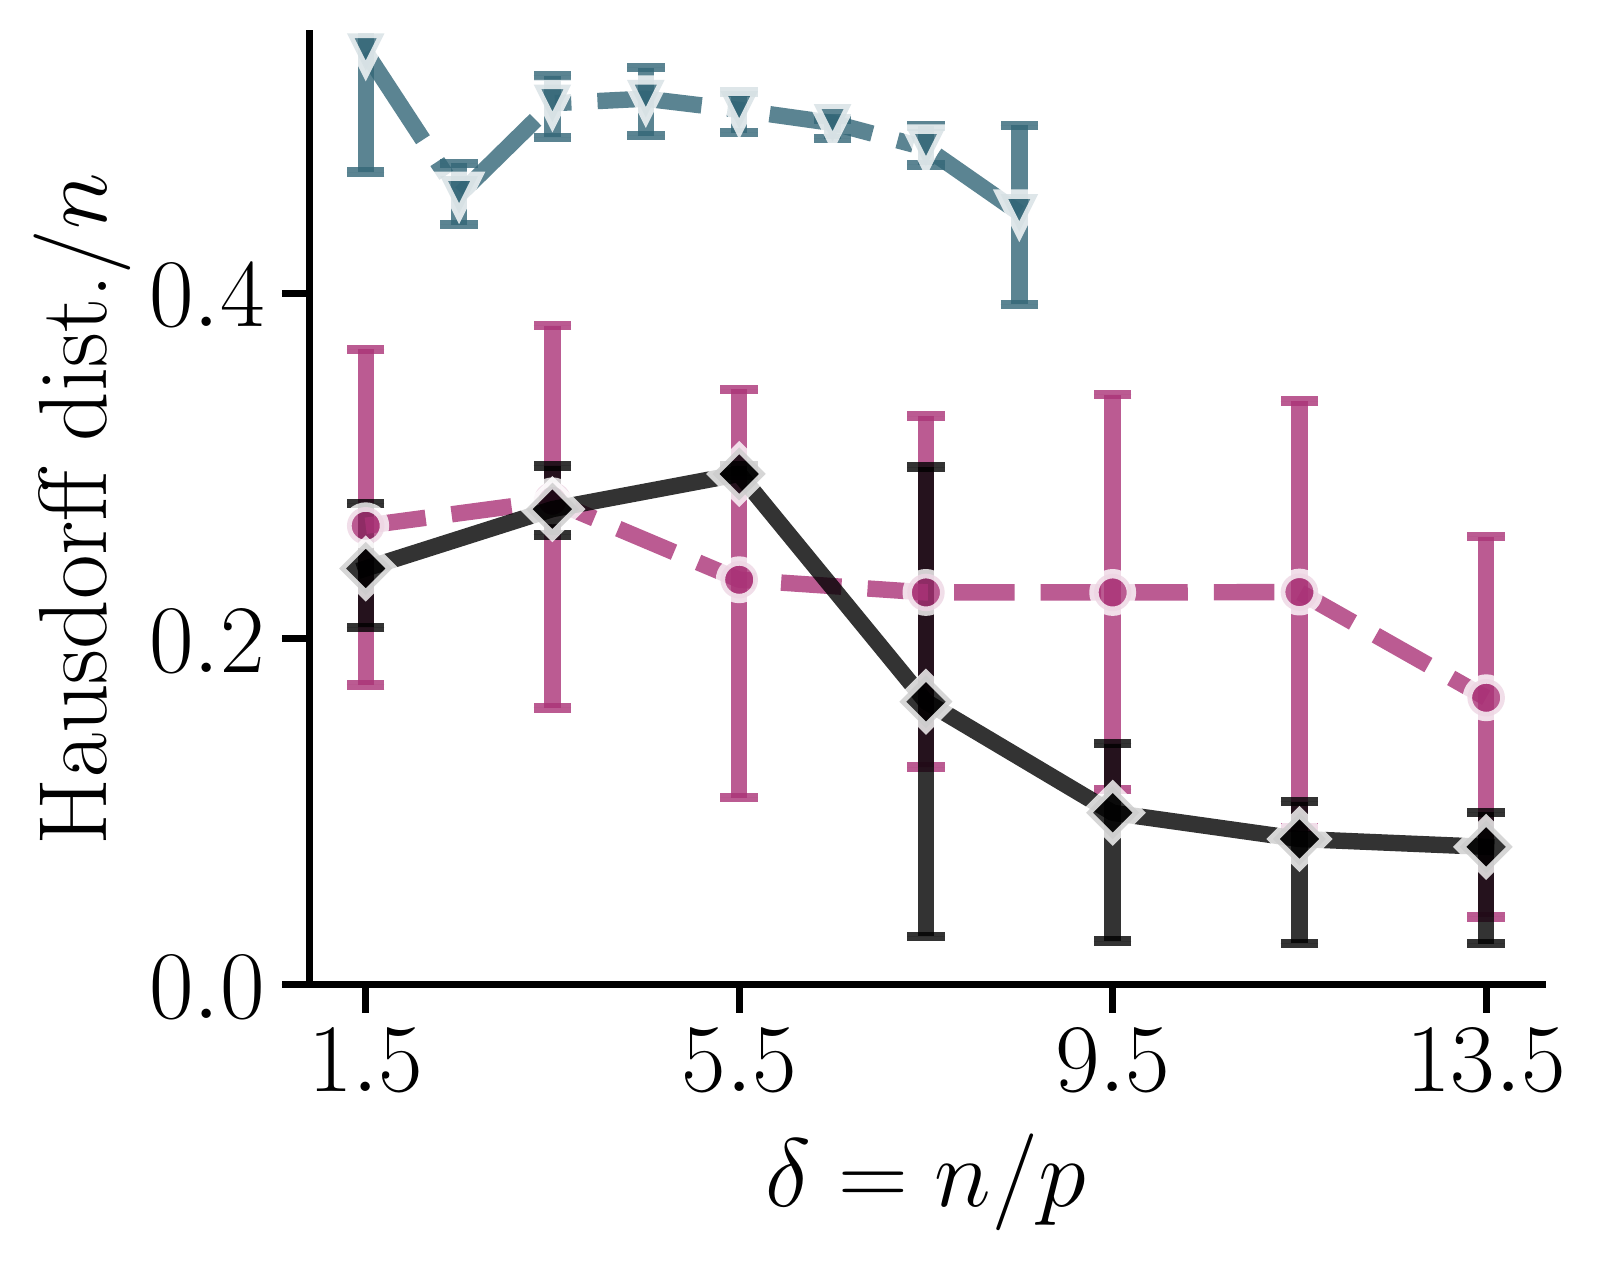

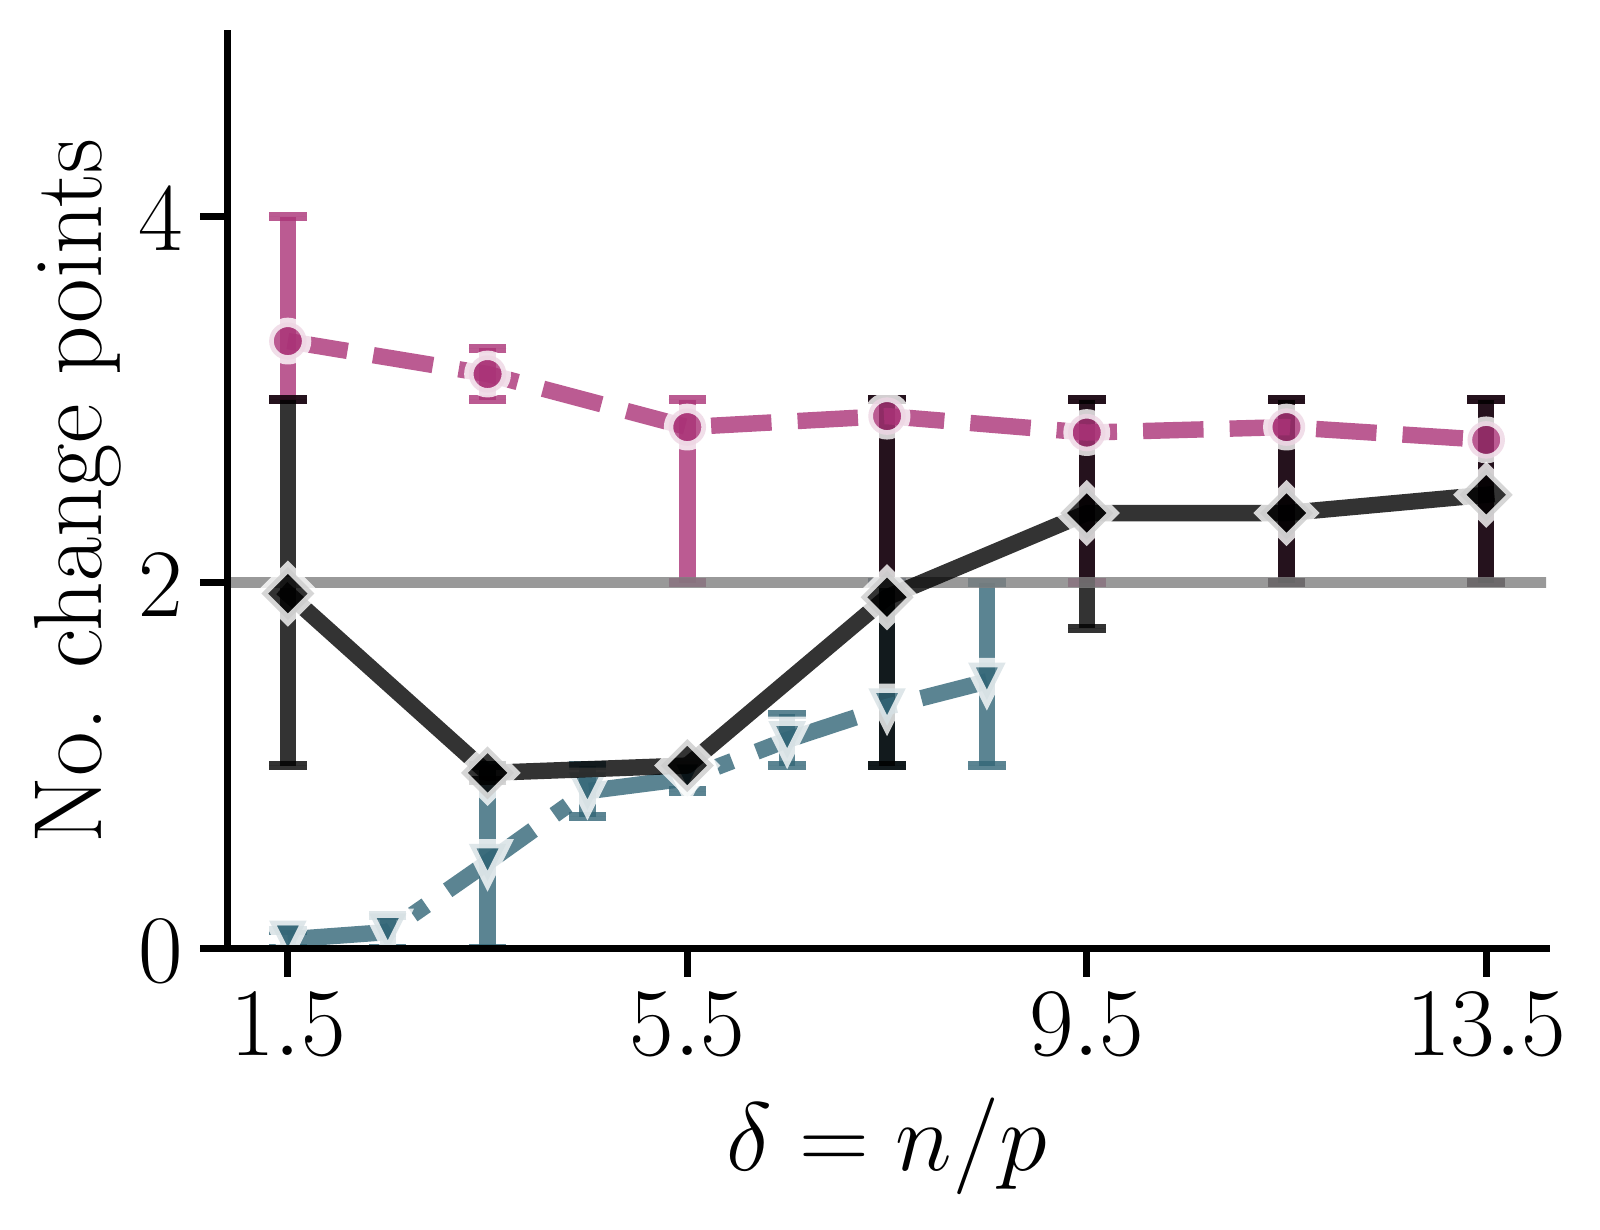

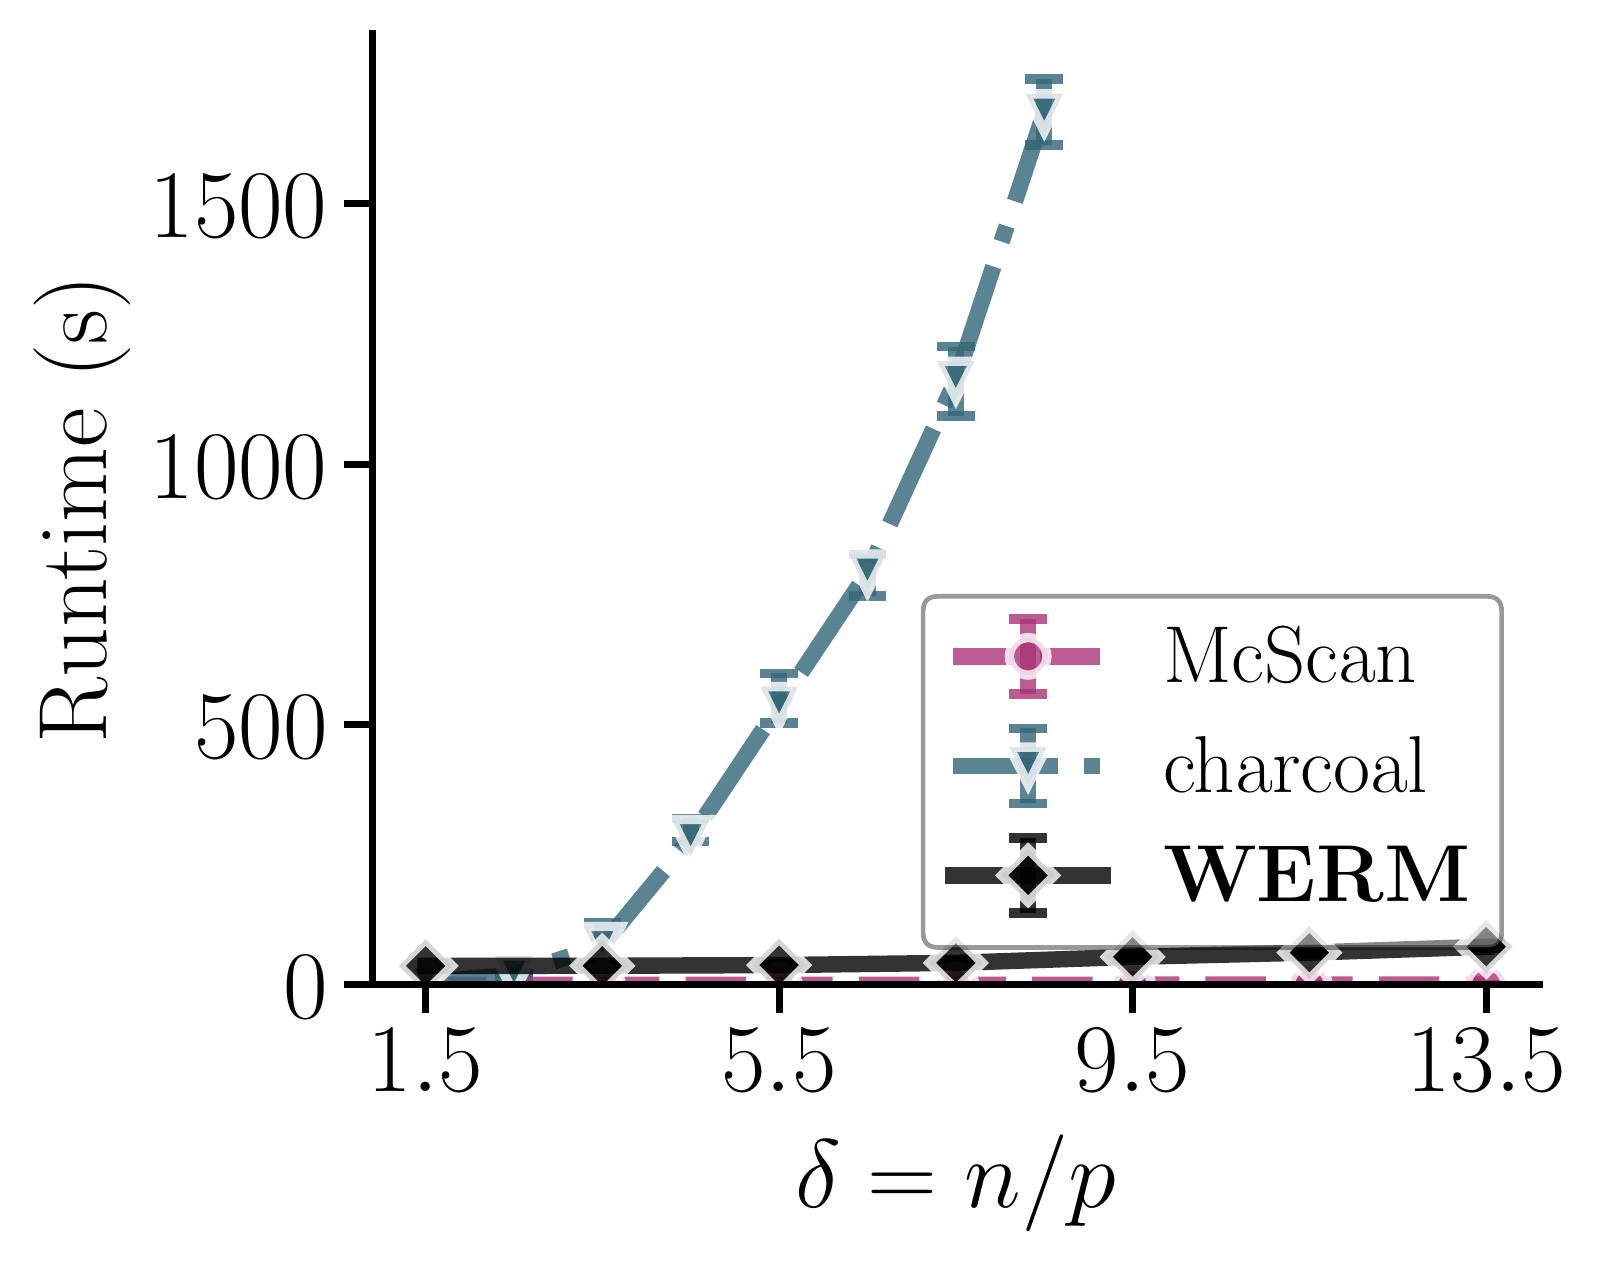

In [4]:
panels = ['figures/M2c_extended_moredeltas_newcolors_alpha03_0205_McScan_charcoal_WERM-unp-10fold_location_p200_L4_noisestd0.31622776601683794_seed42.pdf', 'figures/M2c_extended_moredeltas_newcolors_alpha03_0205_McScan_charcoal_WERM-unp-10fold_size_p200_L4_noisestd0.31622776601683794_seed42.pdf', 'figures/M2c_extended_moredeltas_newcolors_alpha03_0205_McScan_charcoal_WERM-unp-10fold_runtime_p200_L4_noisestd0.31622776601683794_seed42.pdf'] if REGENERATE_FIGURES else ['figures/figure_07/panel_01.pdf', 'figures/figure_07/panel_02.pdf', 'figures/figure_07/panel_03.pdf']
show_panels(panels)


## Figure 8

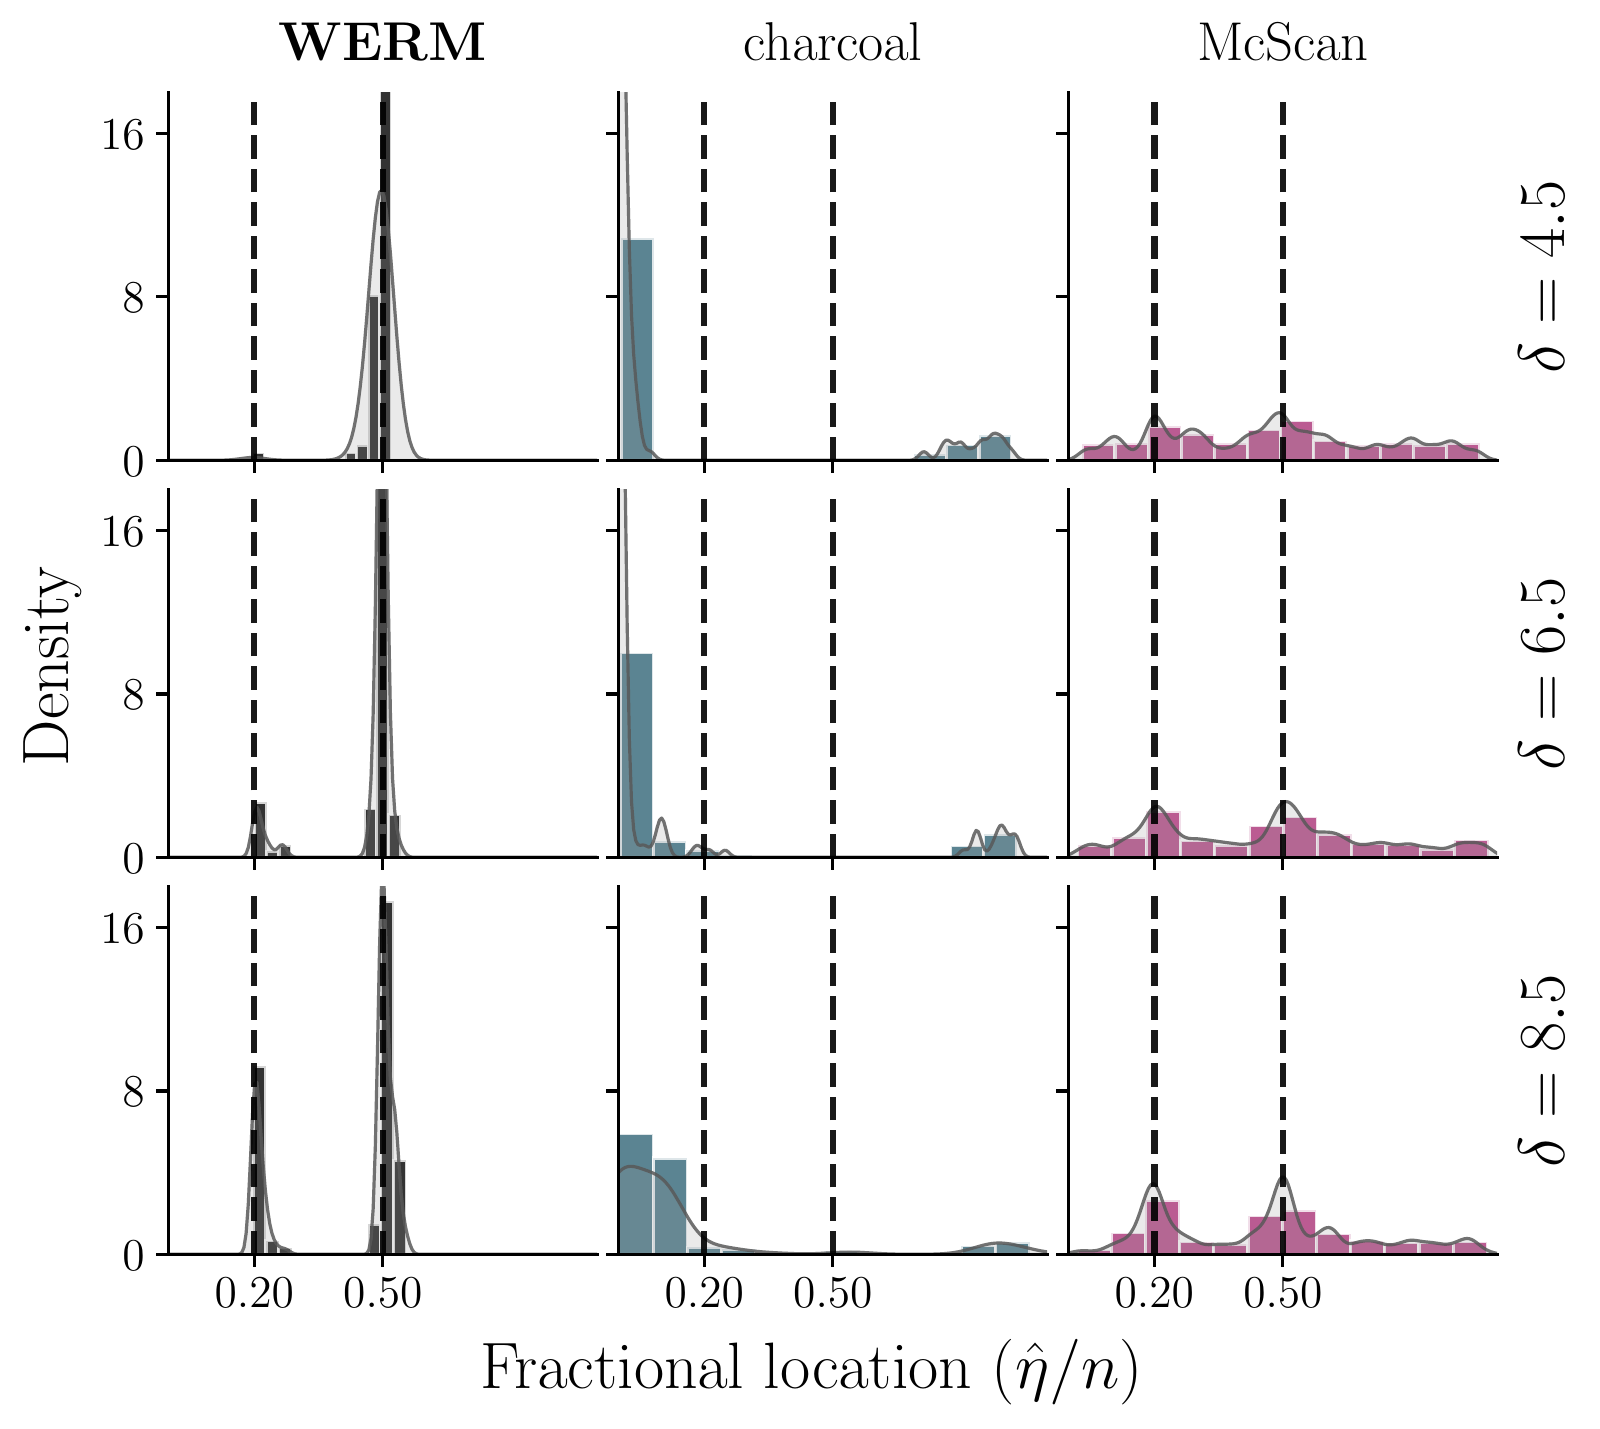

In [5]:
panels = ['figures/M2c_extended_moredeltas_newcolors_alpha03_0205_McScan_charcoal_WERM-unp-10fold_chgpt_histograms_p200_L4_noisestd0.31622776601683794_seed42.pdf'] if REGENERATE_FIGURES else ['figures/figure_08/panel_01.pdf']
show_panels(panels)
